In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import sklearn
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import  StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import  RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import  GradientBoostingRegressor
from sklearn.linear_model import  Ridge
from sklearn.svm import SVR
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier


import seaborn as sns
import graphviz

import keras
import tensorflow as tf
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Dropout
from keras.layers import Flatten
from keras.utils import np_utils


In [ ]:
df = pd.read_csv('abalone.csv')
df.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,"0,455","0,365","0,095","0,514","0,2245","0,101","0,15",15
1,M,"0,35","0,265","0,09","0,2255","0,0995","0,0485","0,07",7
2,F,"0,53","0,42","0,135","0,677","0,2565","0,1415","0,21",9
3,M,"0,44","0,365","0,125","0,516","0,2155","0,114","0,155",10
4,I,"0,33","0,255","0,08","0,205","0,0895","0,0395","0,055",7


In [ ]:
df =  df.replace(',', '.', regex=True)

df = df.apply(pd.to_numeric, errors='ignore')

# analise estatistica dos dados

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   object 
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole weight    4177 non-null   float64
 5   Shucked weight  4177 non-null   float64
 6   Viscera weight  4177 non-null   float64
 7   Shell weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 293.8+ KB


In [ ]:
df.describe()

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
count,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,9.933684
std,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,8.000000
50%,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,9.000000
75%,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,11.000000
max,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


Text(0.5, 1.0, 'Rings')

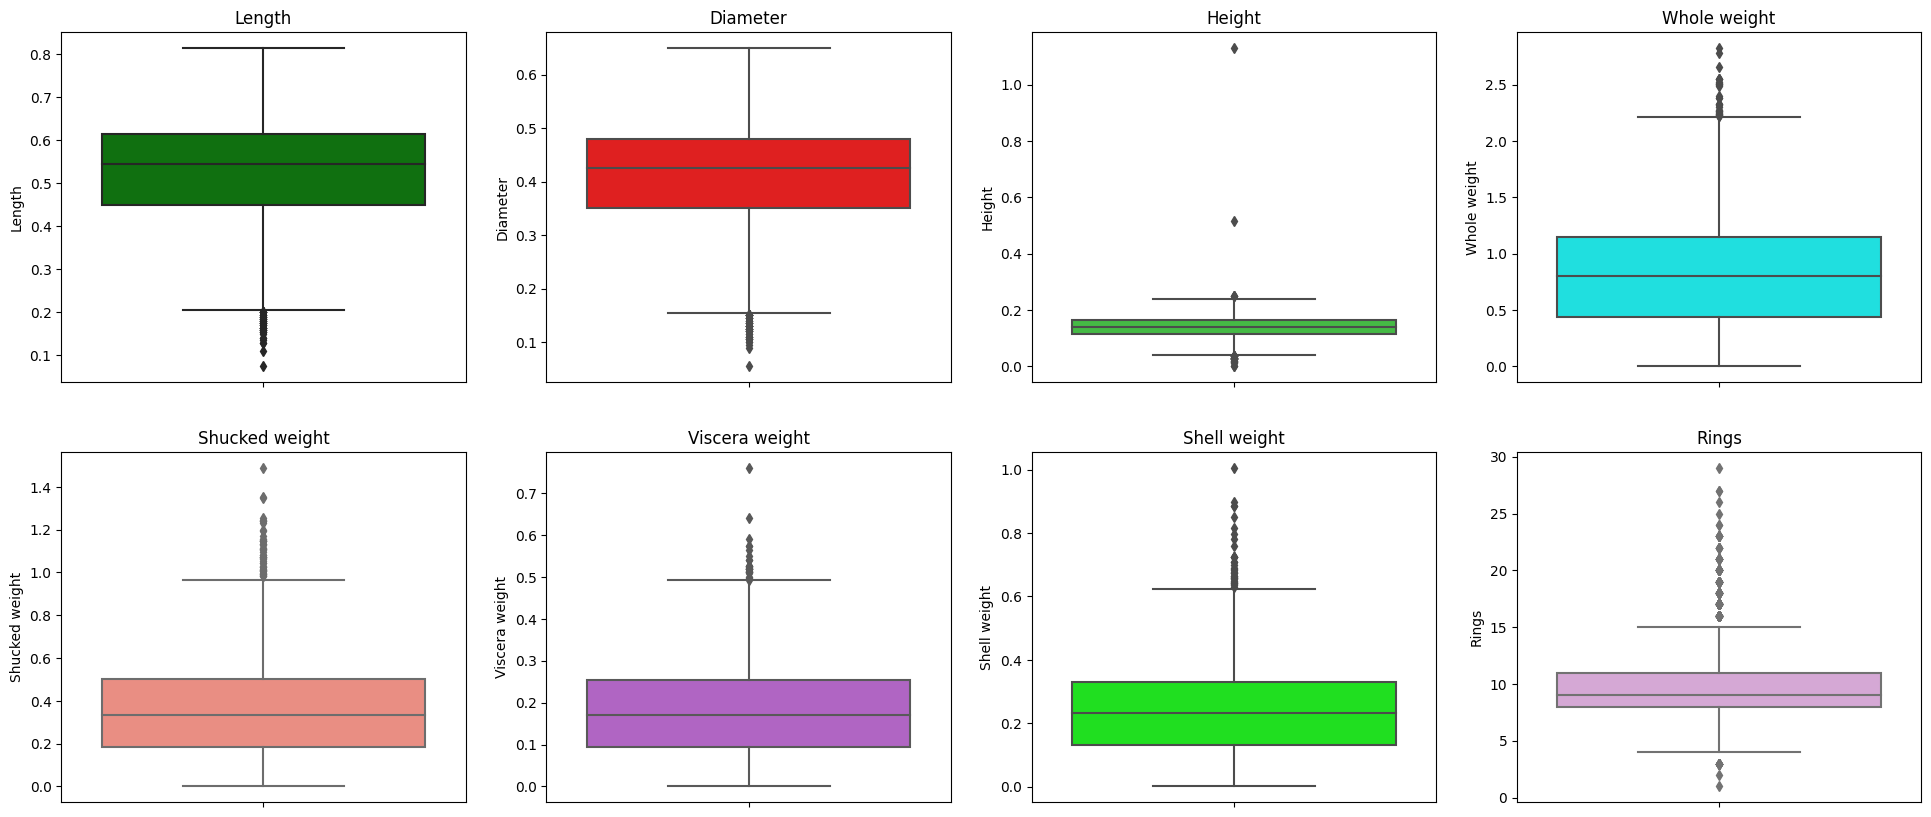

In [ ]:
fig, ((ax1, ax2, ax3, ax4), (ax5, ax6, ax7, ax8)) = plt.subplots(nrows= 2, ncols = 4, figsize = (24,10))
sns.boxplot(ax = ax1, y = 'Length', data = df, color = 'green')
ax1.set_title('Length')
sns.boxplot(ax = ax2, y = 'Diameter', data = df, color = 'red')
ax2.set_title('Diameter')
sns.boxplot(ax = ax3, y = 'Height', data = df, color = 'limegreen')
ax3.set_title('Height')
sns.boxplot(ax = ax4, y = 'Whole weight', data = df, color = 'cyan')
ax4.set_title('Whole weight')
sns.boxplot(ax = ax5, y = 'Shucked weight', data = df, color = 'salmon')
ax5.set_title('Shucked weight')
sns.boxplot(ax = ax6, y = 'Viscera weight', data = df, color = 'mediumorchid')
ax6.set_title('Viscera weight')
sns.boxplot(ax = ax7, y = 'Shell weight', data = df, color = 'lime')
ax7.set_title('Shell weight')
sns.boxplot(ax = ax8, y = 'Rings', data = df, color = 'plum')
ax8.set_title('Rings')

array([[<AxesSubplot:title={'center':'Length'}>,
        <AxesSubplot:title={'center':'Diameter'}>,
        <AxesSubplot:title={'center':'Height'}>,
        <AxesSubplot:title={'center':'Whole weight'}>],
       [<AxesSubplot:title={'center':'Shucked weight'}>,
        <AxesSubplot:title={'center':'Viscera weight'}>,
        <AxesSubplot:title={'center':'Shell weight'}>,
        <AxesSubplot:title={'center':'Rings'}>]], dtype=object)

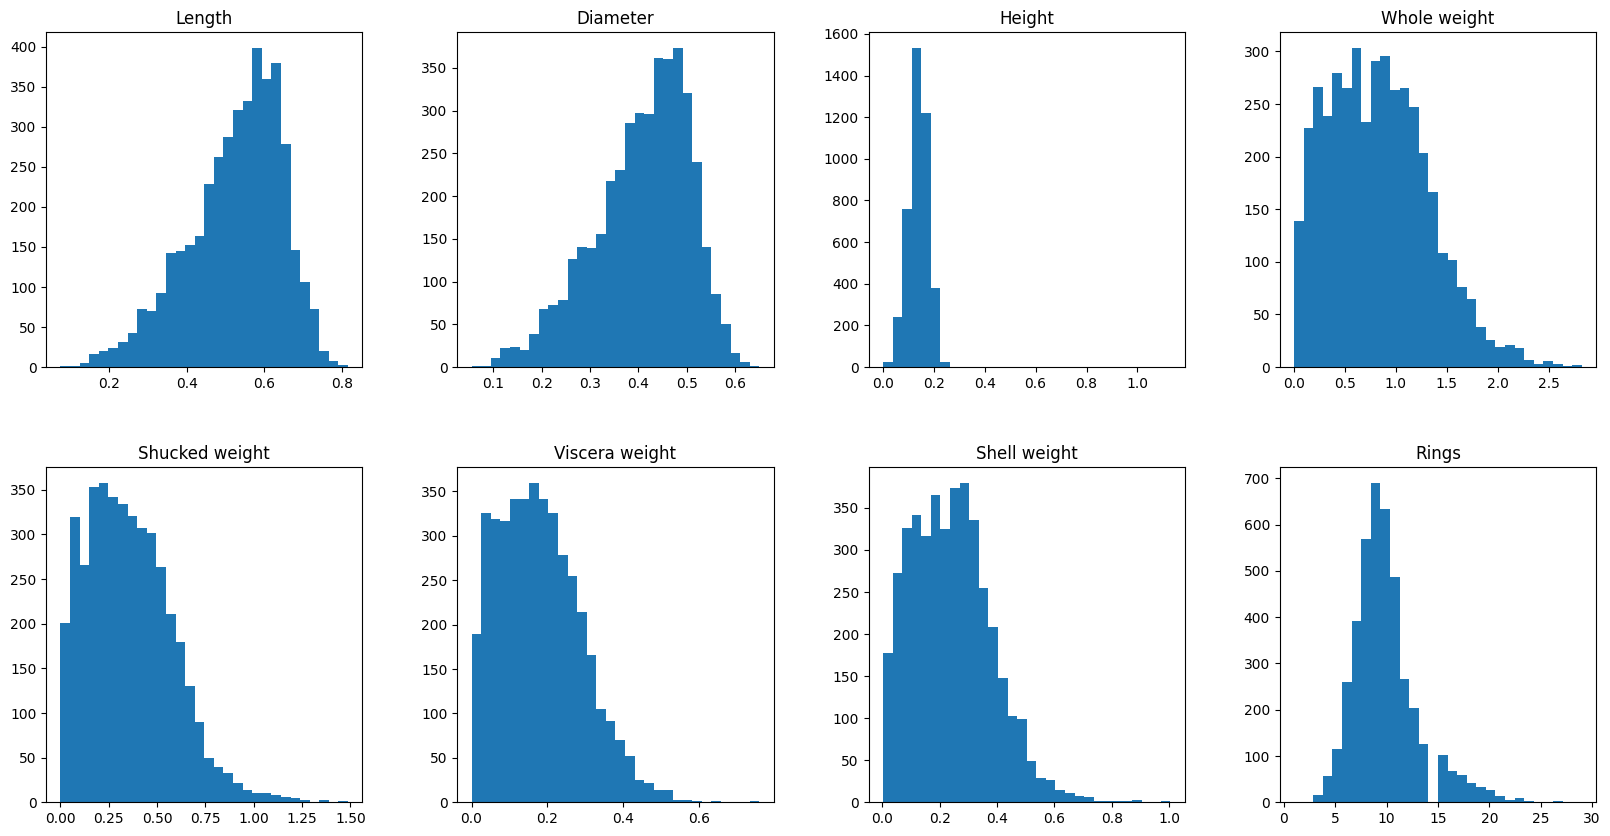

In [ ]:
df.hist(figsize=(20,10), grid=False, layout=(2, 4), bins = 30)

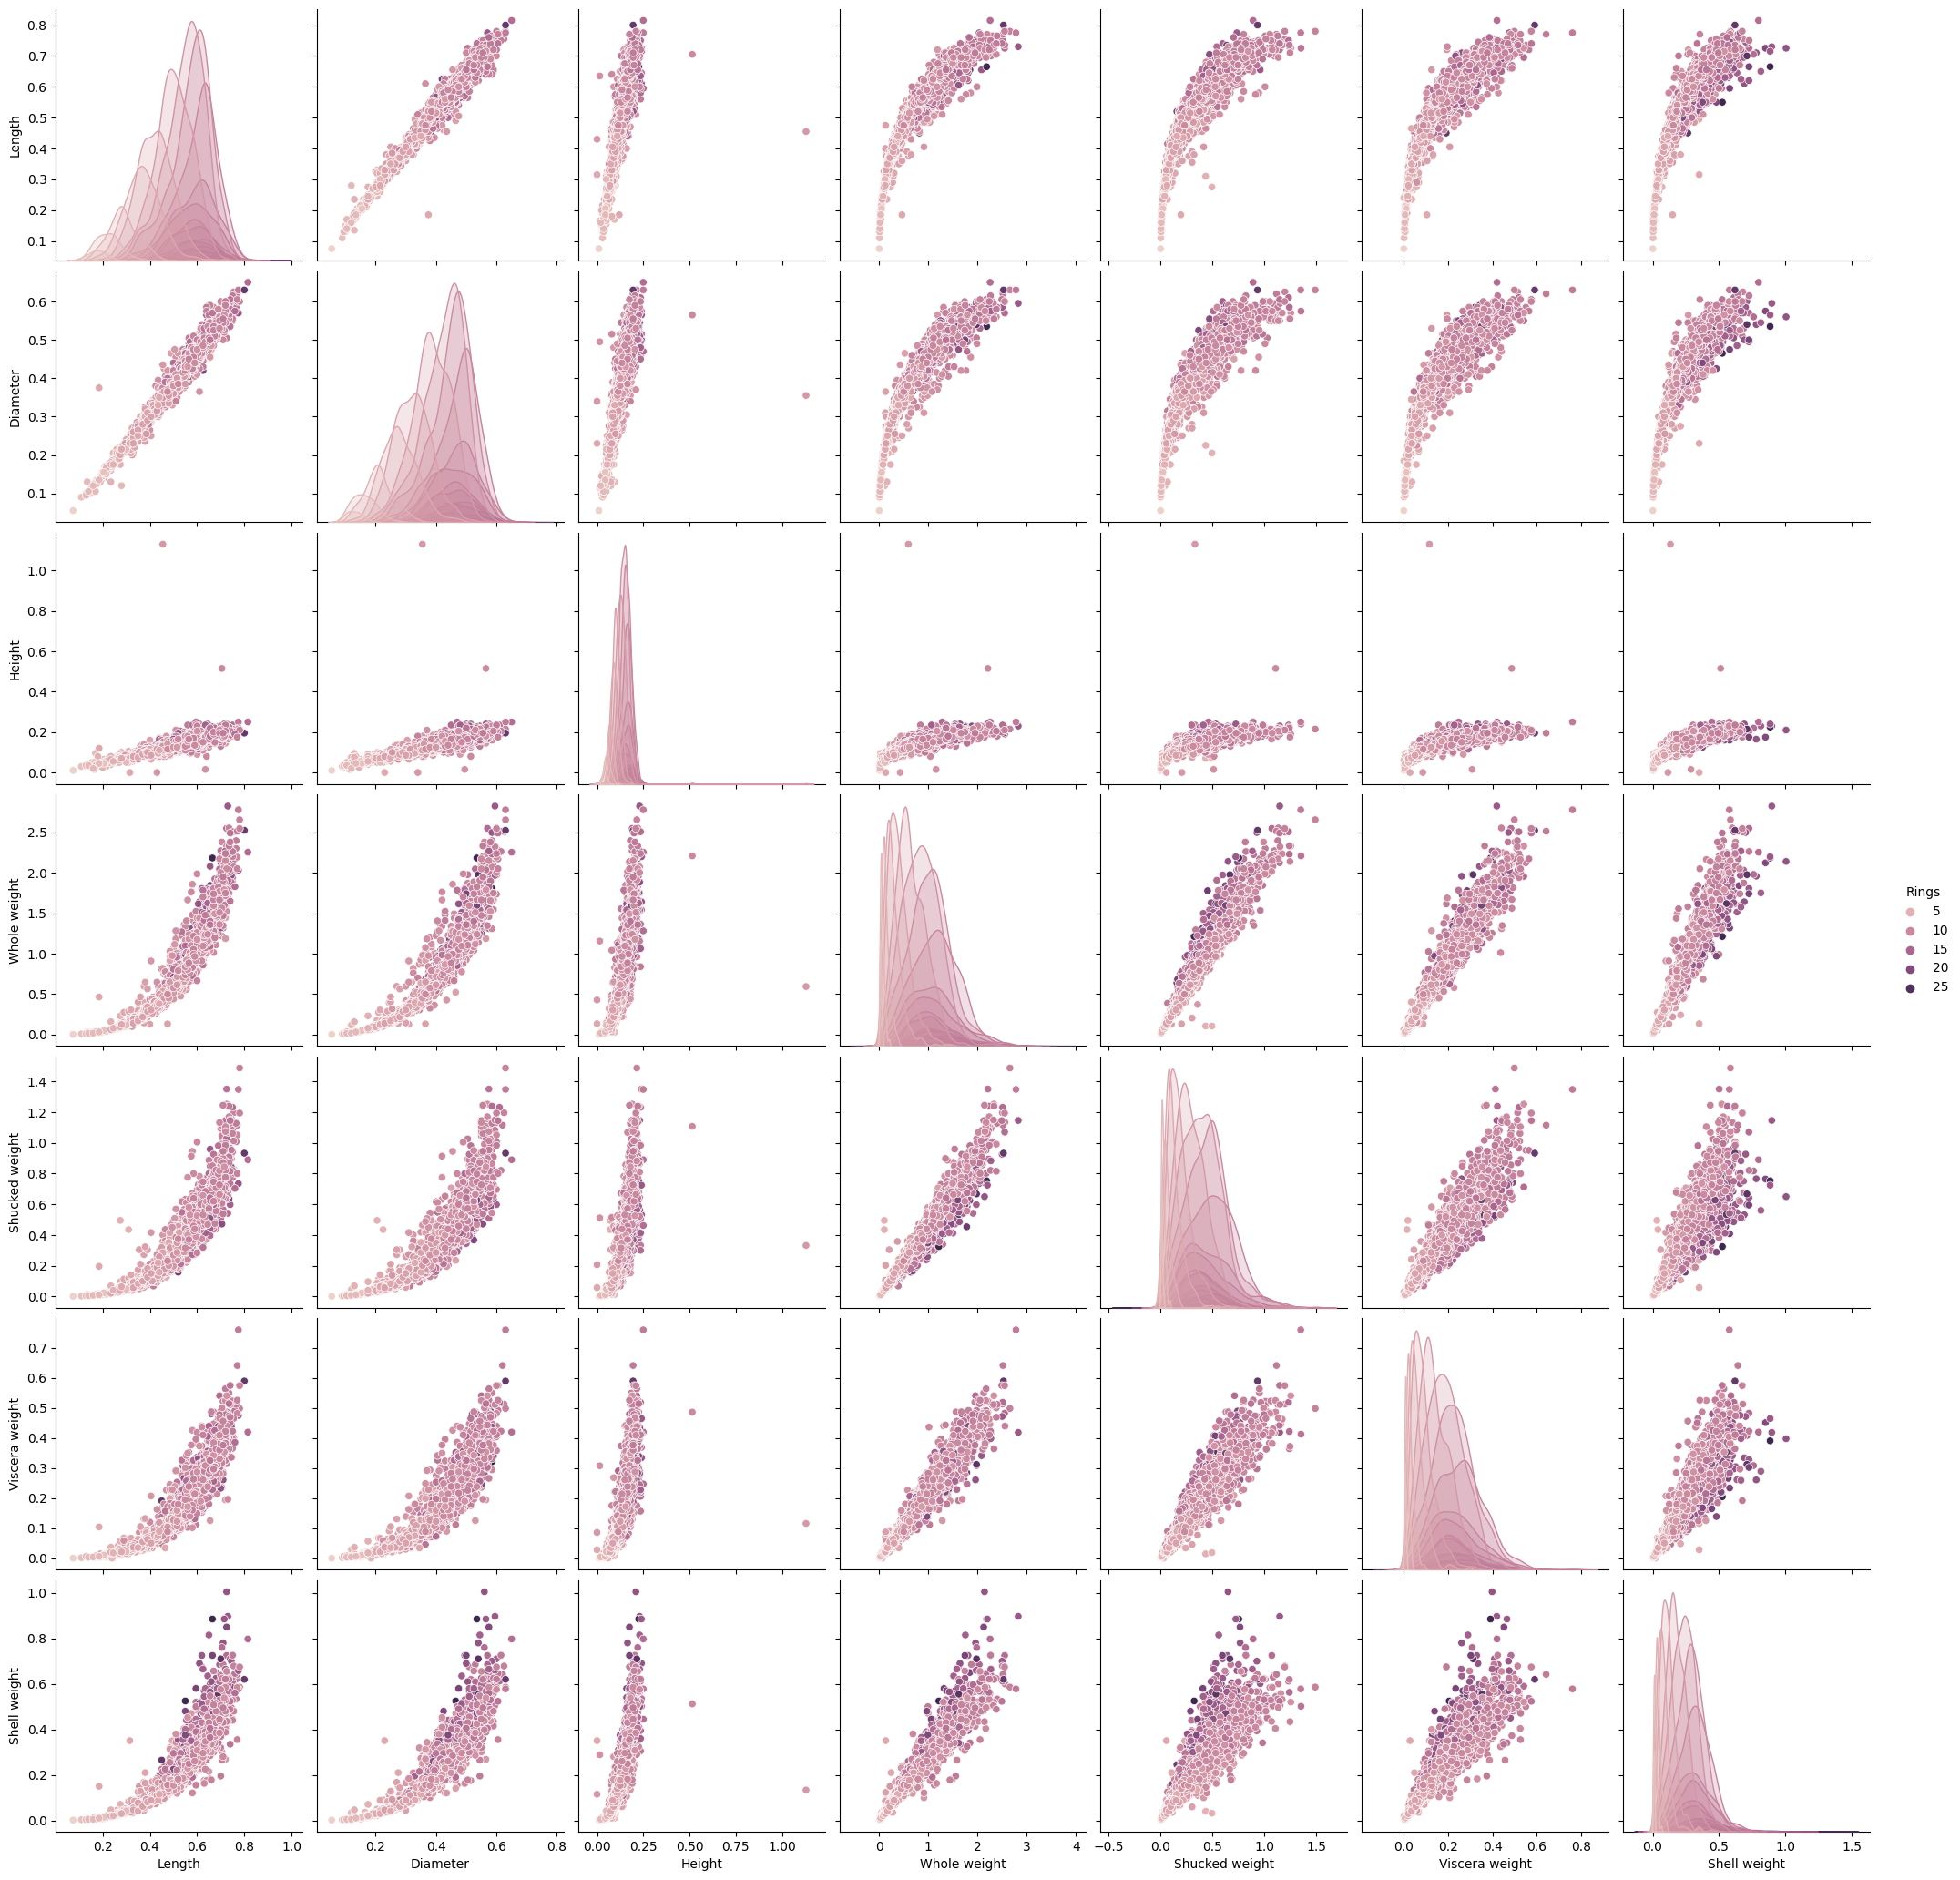

In [ ]:
sns.pairplot(df, hue="Rings", height=3)

# as variaveis contem alto correlação entre elas, o que pode causa problema no modelo e um pior desempenho

<AxesSubplot:>

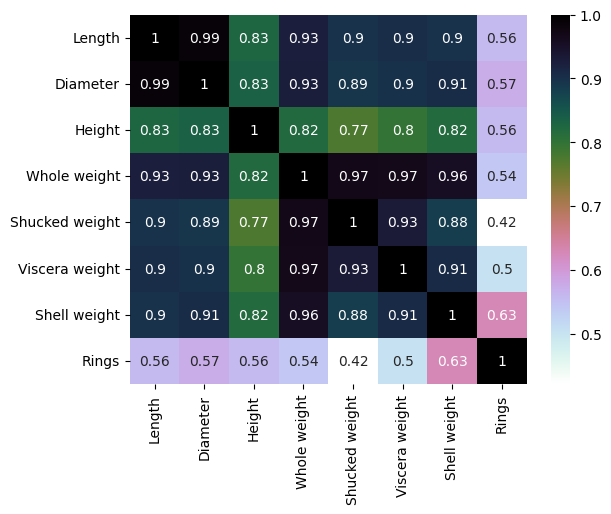

In [ ]:
sns.heatmap(df.corr(), annot=True, cmap='cubehelix_r')

# transformando a variavel Sex em dado númerico

In [ ]:
label_en = LabelEncoder()
df['Sex'] = label_en.fit_transform(df['Sex'])

In [ ]:
df

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,2,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.1500,15
1,2,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.0700,7
2,0,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.2100,9
3,2,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.1550,10
4,1,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.0550,7
...,...,...,...,...,...,...,...,...,...
4172,0,0.565,0.450,0.165,0.8870,0.3700,0.2390,0.2490,11
4173,2,0.590,0.440,0.135,0.9660,0.4390,0.2145,0.2605,10
4174,2,0.600,0.475,0.205,1.1760,0.5255,0.2875,0.3080,9
4175,0,0.625,0.485,0.150,1.0945,0.5310,0.2610,0.2960,10


In [ ]:
X = df.drop(['Rings'], axis = 1)
y = df['Rings']

# transformando o conjunto de dados para média de 0 e um desvio padrão de 1 usando StandardScaler

In [ ]:
standardScale = StandardScaler()
standardScale.fit_transform(X)
X.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight
0,2,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150
1,2,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070
2,0,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210
3,2,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155
4,1,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055


# modelo com todas as variaveis

In [ ]:
np.random.seed(10)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 123)
def rmse_cv(model, X_train, y):
    rmse =- (cross_val_score(model, X_train, y, scoring='neg_mean_squared_error', cv=5))
    return(rmse*100)

models = [LinearRegression(),
             Ridge(),
             SVR(),
             RandomForestRegressor(),
             GradientBoostingRegressor(),
             KNeighborsRegressor(n_neighbors = 4),]

names = ['LR','Ridge','svm','GNB','RF','GB','KNN']
result = [0]*len(names)
for model,name,i in zip(models,names,range(0,len(names))):
    result[i] = model.fit(X_train, y_train)
    print("{}    : {}".format(name,result[i]))
    y_pred = result[i].predict(X_test)
    print( "RMSE : %.4g" % mean_squared_error(y_test, y_pred))
    print( "R2 Score (Train): %f" % r2_score(y_test, y_pred))


LR    : LinearRegression()
RMSE : 4.637
R2 Score (Train): 0.524027
Ridge    : Ridge()
RMSE : 4.635
R2 Score (Train): 0.524189
svm    : SVR()
RMSE : 4.859
R2 Score (Train): 0.501238
GNB    : RandomForestRegressor()
RMSE : 4.509
R2 Score (Train): 0.537148
RF    : GradientBoostingRegressor()
RMSE : 4.518
R2 Score (Train): 0.536205
GB    : KNeighborsRegressor(n_neighbors=4)
RMSE : 4.915
R2 Score (Train): 0.495468


# O modelo que apresentou melhor resultado foi o Gradient Boosting Regressor com um r² de 0.537

# selecionando as 5 melhores variaveis para entrar no modelo e separando com conjuto de dados em 75% para o treinamento e 25% para o teste

In [ ]:
selectkBest = SelectKBest(mutual_info_regression, k=5)
X_new = selectkBest.fit_transform(X, y)

X_train, X_test, y_train, y_test = train_test_split(X_new, y, test_size = 0.25, random_state = 123)

In [ ]:
X_train

array([[0.245 , 0.18  , 0.065 , 0.0635, 0.02  ],
       [0.44  , 0.325 , 0.1   , 0.4165, 0.11  ],
       [0.405 , 0.305 , 0.105 , 0.3625, 0.125 ],
       ...,
       [0.585 , 0.45  , 0.18  , 0.7995, 0.237 ],
       [0.575 , 0.46  , 0.165 , 1.065 , 0.2815],
       [0.625 , 0.475 , 0.16  , 1.3335, 0.319 ]])

# rodando os modelos e comparando os resultados atraves das metricas r² e rmse

In [ ]:
np.random.seed(100)
def rmse_cv(model, X_train, y):
    rmse =- (cross_val_score(model, X_train, y, scoring='neg_mean_squared_error', cv=5))
    return(rmse*100)

models = [LinearRegression(),
             Ridge(),
             SVR(),
             RandomForestRegressor(),
             GradientBoostingRegressor(),
             KNeighborsRegressor(n_neighbors = 4),]

names = ['LR','Ridge','svm','GNB','RF','GB','KNN']
result = [0]*len(names)

for model,name,i in zip(models,names,range(0,len(names))):
    result[i] = model.fit(X_train, y_train)
    print("{}    : {}".format(name,result[i]))
    y_pred = result[i].predict(X_test)

    print( "RMSE : %.4g" % mean_squared_error(y_test, y_pred))
    print( "R2 Score (Train): %f" % r2_score(y_test, y_pred))


LR    : LinearRegression()
RMSE : 5.047
R2 Score (Train): 0.481908
Ridge    : Ridge()
RMSE : 5.102
R2 Score (Train): 0.476246
svm    : SVR()
RMSE : 5.287
R2 Score (Train): 0.457267
GNB    : RandomForestRegressor()
RMSE : 5.34
R2 Score (Train): 0.451875
RF    : GradientBoostingRegressor()
RMSE : 4.792
R2 Score (Train): 0.508073
GB    : KNeighborsRegressor(n_neighbors=4)
RMSE : 5.661
R2 Score (Train): 0.418911


# Os modelos com treinados com 5 variáveis preiditora apresentou um monor desempenho comparados modelos usando todas as variáveis  

# retirando alguns outliers

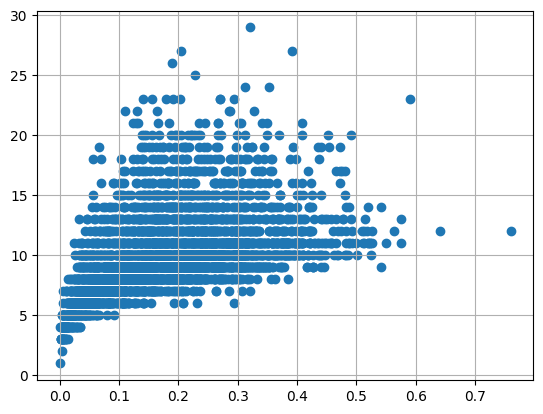

In [ ]:
plt.scatter(x = df['Viscera weight'], y = df['Rings'])
plt.grid(True)

In [ ]:
df.drop(df[(df['Viscera weight']> 0.5) & (df['Rings'] < 20)].index, inplace=True)
df.drop(df[(df['Viscera weight']< 0.5) & (df['Rings'] > 25)].index, inplace=True)

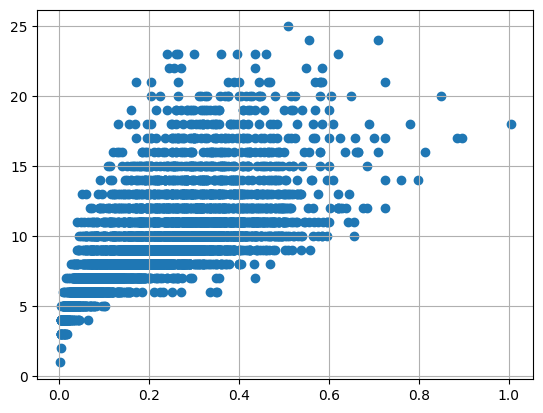

In [ ]:
plt.scatter(x = df['Shell weight'], y = df['Rings'])
plt.grid(True)

In [ ]:
df.drop(df[(df['Shell weight']> 0.6) & (df['Rings'] < 25)].index, inplace=True)
df.drop(df[(df['Shell weight']< 0.8) & (df['Rings'] > 25)].index, inplace=True)

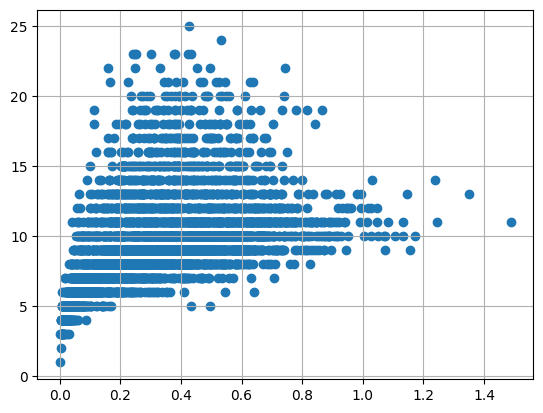

In [ ]:
plt.scatter(x = df['Shucked weight'], y = df['Rings'])
plt.grid(True)

In [ ]:
df.drop(df[(df['Shucked weight']>= 1) & (df['Rings'] < 20)].index, inplace=True)
df.drop(df[(df['Shucked weight']<1) & (df['Rings'] > 20)].index, inplace=True)

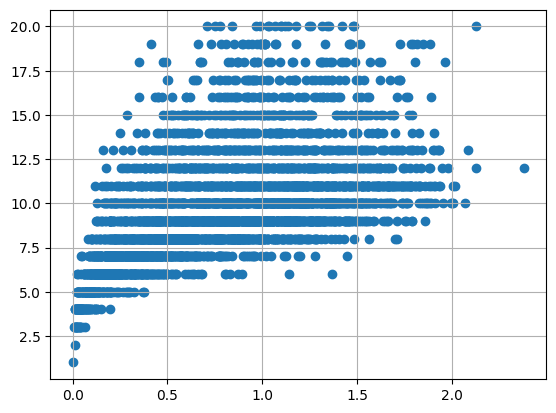

In [ ]:
plt.scatter(x = df['Whole weight'], y = df['Rings'])
plt.grid(True)

In [ ]:
df.drop(df[(df['Whole weight']>= 2.5) & (df['Rings'] < 25)].index, inplace=True)
df.drop(df[(df['Whole weight']<2.5) & (df['Rings'] > 25)].index, inplace=True)

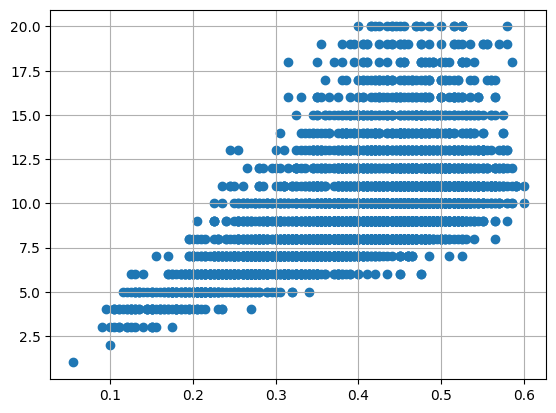

In [ ]:
plt.scatter(x = df['Diameter'], y = df['Rings'])
plt.grid(True)

In [ ]:
df.drop(df[(df['Diameter']<0.1) & (df['Rings'] < 5)].index, inplace=True)
df.drop(df[(df['Diameter']<0.6) & (df['Rings'] > 25)].index, inplace=True)
df.drop(df[(df['Diameter']>=0.6) & (df['Rings']< 25)].index, inplace=True)

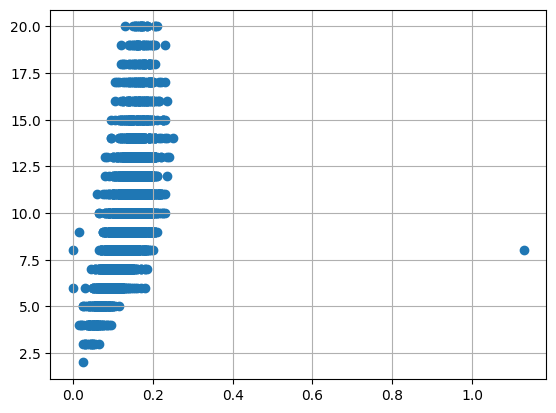

In [ ]:
plt.scatter(x = df['Height'], y = df['Rings'])
plt.grid(True)

In [ ]:
df.drop(df[(df['Height']>0.4) & (df['Rings'] < 15)].index, inplace=True)
df.drop(df[(df['Height']<0.4) & (df['Rings'] > 25)].index, inplace=True)

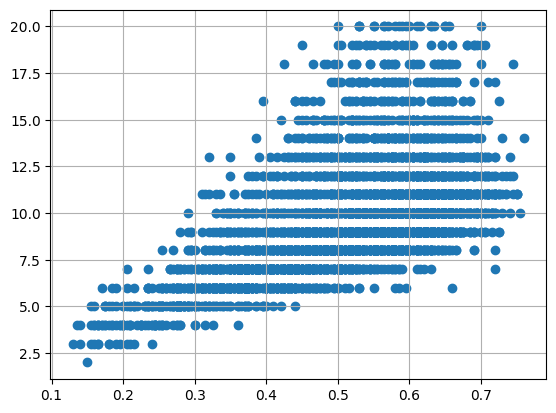

In [ ]:
plt.scatter(x = df['Length'], y = df['Rings'])
plt.grid(True)

In [ ]:
df.drop(df[(df['Length']<0.1) & (df['Rings'] < 5)].index, inplace=True)
df.drop(df[(df['Length']<0.8) & (df['Rings'] > 25)].index, inplace=True)
df.drop(df[(df['Length']>=0.8) & (df['Rings']< 25)].index, inplace=True)

In [ ]:
X = df.drop(['Rings'], axis = 1)
y = df['Rings']

# transformando o conjunto de dados para média de 0 e um desvio padrão de 1 usando StandardScaler

In [ ]:
standardScale = StandardScaler()
standardScale.fit_transform(X)
X.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight
0,2,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150
1,2,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070
2,0,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210
3,2,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155
4,1,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055


# selecionando as 5 melhores variaveis para entrar no modelo e separando com conjuto de dados em 75% para o treinamento e 25% para o teste

In [ ]:
selectkBest = SelectKBest(k=5)
X_new = selectkBest.fit_transform(X, y)

X_train, X_test, y_train, y_test = train_test_split(X_new, y, test_size = 0.25, random_state = 123)

# rodando os modelos e comparando os resultados atraves das metricas r² e rmse

In [ ]:
np.random.seed(10)
def rmse_cv(model, X_train, y):
    rmse =- (cross_val_score(model, X_train, y, scoring='neg_mean_squared_error', cv=5))
    return(rmse*100)

models = [LinearRegression(),
             Ridge(),
             SVR(),
             RandomForestRegressor(),
             GradientBoostingRegressor(),
             KNeighborsRegressor(n_neighbors = 4),]

names = ['LR','Ridge','svm','GNB','RF','GB','KNN']
result = [0]*len(names)
for model,name,i in zip(models,names,range(0,len(names))):
    result[i] = model.fit(X_train, y_train)
    print("{}    : {}".format(name,result[i]))
    y_pred = result[i].predict(X_test)
    print( "RMSE : %.4g" % mean_squared_error(y_test, y_pred))
    print( "R2 Score (Train): %f" % r2_score(y_test, y_pred))


LR    : LinearRegression()
RMSE : 5.056
R2 Score (Train): 0.428803
Ridge    : Ridge()
RMSE : 5.163
R2 Score (Train): 0.416754
svm    : SVR()
RMSE : 5.145
R2 Score (Train): 0.418789
GNB    : RandomForestRegressor()
RMSE : 5.109
R2 Score (Train): 0.422809
RF    : GradientBoostingRegressor()
RMSE : 4.785
R2 Score (Train): 0.459482
GB    : KNeighborsRegressor(n_neighbors=4)
RMSE : 5.537
R2 Score (Train): 0.374463


# Os modelos com 5 variaveis preditoras sem outlier apresentou o pior resultado dentre todos os outros testados

# modelos com todas as variaveis, sem outlier

In [ ]:
np.random.seed(10)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25)
def rmse_cv(model, X_train, y):
    rmse =- (cross_val_score(model, X_train, y, scoring='neg_mean_squared_error', cv=5))
    return(rmse*100)

models = [LinearRegression(),
             Ridge(),
             SVR(),
             RandomForestRegressor(),
             GradientBoostingRegressor(),
             KNeighborsRegressor(n_neighbors = 4),]

names = ['LR','Ridge','svm','GNB','RF','GB','KNN']
result = [0]*len(names)
for model,name,i in zip(models,names,range(0,len(names))):
    result[i] = model.fit(X_train, y_train)
    print("{}    : {}".format(name,result[i]))
    y_pred = result[i].predict(X_test)
    print( "RMSE : %.4g" % mean_squared_error(y_test, y_pred))
    print( "R2 Score (Train): %f" % r2_score(y_test, y_pred))


LR    : LinearRegression()
RMSE : 4.184
R2 Score (Train): 0.520814
Ridge    : Ridge()
RMSE : 4.257
R2 Score (Train): 0.512461
svm    : SVR()
RMSE : 4.272
R2 Score (Train): 0.510744
GNB    : RandomForestRegressor()
RMSE : 4.089
R2 Score (Train): 0.531768
RF    : GradientBoostingRegressor()
RMSE : 3.935
R2 Score (Train): 0.549328
GB    : KNeighborsRegressor(n_neighbors=4)
RMSE : 4.177
R2 Score (Train): 0.521706


# Os modelos com todas as variáveis sem outlier apresentou melhor resultado de forma geral, sendo o Gradient Boosting Regressor o que obteve o melhor desempenho com r² = 0,549

# Modelos para o problema de Classificação

# transformando y em uma variavel categorica para a classificação

In [ ]:
X = df.drop(['Rings'], axis = 1)
y = tf.keras.utils.to_categorical(df['Rings'])

In [ ]:
y.shape

(4049, 21)

# transformando o conjunto de dados para média de 0 e um desvio padrão de 1 usando StandardScaler

In [ ]:
standardScale = StandardScaler()
standardScale.fit_transform(X)
X.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight
0,2,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150
1,2,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070
2,0,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210
3,2,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155
4,1,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055


In [ ]:
y.shape

(4049, 21)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 123)

In [ ]:
model = keras.Sequential([
    keras.layers.Dense(512, input_dim=X.shape[1], activation='relu'),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(y.shape[1], activation='softmax')
])
model.compile(optimizer='sgd',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 512)               4608      
                                                                 
 dense_1 (Dense)             (None, 128)               65664     
                                                                 
 dense_2 (Dense)             (None, 21)                2709      
                                                                 
Total params: 72,981
Trainable params: 72,981
Non-trainable params: 0
_________________________________________________________________


In [ ]:
model.fit(X_train, y_train, epochs=200)

Epoch 1/200
95/95 [==============================] - 1s 2ms/step - loss: 2.8759 - accuracy: 0.1624
Epoch 2/200
95/95 [==============================] - 0s 2ms/step - loss: 2.6411 - accuracy: 0.1677
Epoch 3/200
95/95 [==============================] - 0s 2ms/step - loss: 2.5297 - accuracy: 0.1746
Epoch 4/200
95/95 [==============================] - 0s 2ms/step - loss: 2.4795 - accuracy: 0.1736
Epoch 5/200
95/95 [==============================] - 0s 2ms/step - loss: 2.4494 - accuracy: 0.1808
Epoch 6/200
95/95 [==============================] - 0s 3ms/step - loss: 2.4259 - accuracy: 0.1891
Epoch 7/200
95/95 [==============================] - 0s 3ms/step - loss: 2.4073 - accuracy: 0.1785
Epoch 8/200
95/95 [==============================] - 0s 3ms/step - loss: 2.3906 - accuracy: 0.1891
Epoch 9/200
95/95 [==============================] - 0s 3ms/step - loss: 2.3754 - accuracy: 0.1897
Epoch 10/200
95/95 [==============================] - 0s 3ms/step - loss: 2.3604 - accuracy: 0.1933
Epoch 11/

95/95 [==============================] - 0s 2ms/step - loss: 2.0302 - accuracy: 0.2661
Epoch 84/200
95/95 [==============================] - 0s 3ms/step - loss: 2.0287 - accuracy: 0.2589
Epoch 85/200
95/95 [==============================] - 0s 3ms/step - loss: 2.0266 - accuracy: 0.2760
Epoch 86/200
95/95 [==============================] - 0s 2ms/step - loss: 2.0264 - accuracy: 0.2717
Epoch 87/200
95/95 [==============================] - 0s 2ms/step - loss: 2.0249 - accuracy: 0.2658
Epoch 88/200
95/95 [==============================] - 0s 3ms/step - loss: 2.0230 - accuracy: 0.2645
Epoch 89/200
95/95 [==============================] - 0s 3ms/step - loss: 2.0228 - accuracy: 0.2635
Epoch 90/200
95/95 [==============================] - 0s 3ms/step - loss: 2.0202 - accuracy: 0.2691
Epoch 91/200
95/95 [==============================] - 0s 3ms/step - loss: 2.0194 - accuracy: 0.2684
Epoch 92/200
95/95 [==============================] - 0s 2ms/step - loss: 2.0179 - accuracy: 0.2701
Epoch 93/200


95/95 [==============================] - 0s 2ms/step - loss: 1.9240 - accuracy: 0.2783
Epoch 165/200
95/95 [==============================] - 0s 2ms/step - loss: 1.9220 - accuracy: 0.2806
Epoch 166/200
95/95 [==============================] - 0s 2ms/step - loss: 1.9209 - accuracy: 0.2790
Epoch 167/200
95/95 [==============================] - 0s 2ms/step - loss: 1.9194 - accuracy: 0.2770
Epoch 168/200
95/95 [==============================] - 0s 2ms/step - loss: 1.9168 - accuracy: 0.2826
Epoch 169/200
95/95 [==============================] - 0s 2ms/step - loss: 1.9169 - accuracy: 0.2813
Epoch 170/200
95/95 [==============================] - 0s 2ms/step - loss: 1.9156 - accuracy: 0.2882
Epoch 171/200
95/95 [==============================] - 0s 2ms/step - loss: 1.9145 - accuracy: 0.2869
Epoch 172/200
95/95 [==============================] - 0s 2ms/step - loss: 1.9141 - accuracy: 0.2724
Epoch 173/200
95/95 [==============================] - 0s 2ms/step - loss: 1.9122 - accuracy: 0.2826
Epoc

In [ ]:
test_loss, test_acc = model.evaluate(X_test,  y_test, verbose=2)

print('\nTest accuracy:', test_acc)

32/32 - 0s - loss: 1.9745 - accuracy: 0.2695 - 270ms/epoch - 8ms/step

Test accuracy: 0.26949653029441833


In [ ]:
error_rate = []
for i in range(1,40):
    knn = KNeighborsClassifier(n_neighbors= i)
    knn.fit(X_train, y_train)
    y_predi = knn.predict(X_test)
    error_rate.append(np.mean(y_test != y_predi))

plt.figure(figsize = (10,8))
print("Testing Score:", error_rate[-1])
#plt.plot(range(1,40), error_rate, color='blue', linestyle='dashed', marker='o', markerfacecolor='red', markersize=10)

Testing Score: 0.24876604146100692


<Figure size 1000x800 with 0 Axes>

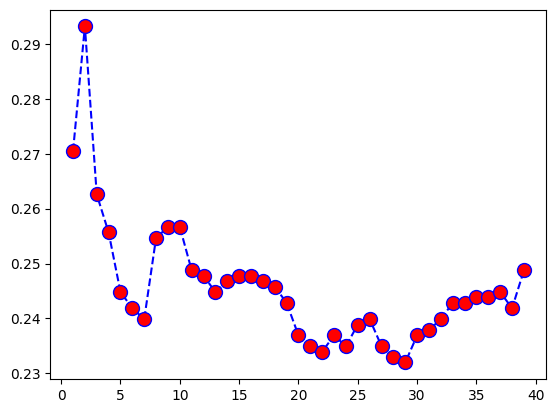

In [ ]:
plt.plot(range(1,40), error_rate, color='blue', linestyle='dashed', marker='o', markerfacecolor='red', markersize=10)

# Os modelos de classificação apresentão acurácia baixa, talvez devido ao número elevado de classes para se prever e a alta correlação entre os dados preditores

# transformando em um problema de classificação com duas classes

In [ ]:
df['Rings'].mean()

9.761669548036553

In [ ]:
df_1 = df.copy()
Rings = []
for i in df_1['Rings']:
    if i > 9.76:
        Rings.append('1')
    else:
        Rings.append('0')
df_1['Rings'] = Rings
df_1.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,2,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,1
1,2,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,0
2,0,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,0
3,2,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,1
4,1,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,0


In [ ]:
X = df_1.drop(['Rings'], axis = 1)
y = df_1['Rings']

In [ ]:
standardScale = StandardScaler()
standardScale.fit_transform(X)
X.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight
0,2,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150
1,2,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070
2,0,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210
3,2,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155
4,1,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 123)

In [ ]:
np.random.seed(10)
def rmse_cv(model, X_train, y):
    rmse =- (cross_val_score(model, X_train, y, scoring='neg_mean_squared_error', cv=5))
    return(rmse*100)

models = [LogisticRegression(),
          SVC(C = 1, gamma= 1),
          DecisionTreeClassifier(max_depth = 5),
          RandomForestClassifier(n_estimators= 150, max_depth= 5),
          AdaBoostClassifier(n_estimators= 100),
          GradientBoostingClassifier(n_estimators= 200, max_depth = 2, min_samples_leaf= 2),]

names = ['Logistic Regression','SVC', 'Decision Tree','Random Forest','AdaBoost','Gradient Boosting']
result = [0]*len(names)
for model,name,i in zip(models,names,range(0,len(names))):
    result[i] = model.fit(X_train, y_train)
    print("{}    : {}".format(name,result[i]))


    result[i] = model.fit(X_train, y_train)
    lr_test_acc = result[i].score(X_test, y_test)

    lr_train_acc = result[i].score(X_train, y_train)
    print('Training Score: ', lr_train_acc)
    print('Testing Score: ', lr_test_acc)
    print('\n')

Logistic Regression    : LogisticRegression()
Training Score:  0.7720685111989459
Testing Score:  0.7561697926949654


SVC    : SVC(C=1, gamma=1)
Training Score:  0.7707509881422925
Testing Score:  0.7423494570582428


Decision Tree    : DecisionTreeClassifier(max_depth=5)
Training Score:  0.7987483530961792
Testing Score:  0.7601184600197434


Random Forest    : RandomForestClassifier(max_depth=5, n_estimators=150)
Training Score:  0.8096179183135704
Testing Score:  0.7670286278381047


AdaBoost    : AdaBoostClassifier(n_estimators=100)
Training Score:  0.7974308300395256
Testing Score:  0.7670286278381047


Gradient Boosting    : GradientBoostingClassifier(max_depth=2, min_samples_leaf=2, n_estimators=200)
Training Score:  0.8260869565217391
Testing Score:  0.7818361303060217


